# 01 — EDA do GSE186575 (notebook de testes)

Exploração inicial do dataset **GSE186575** (cfMeDIP-seq de plasma: câncer colorretal, gástrico e controles saudáveis).
Objetivo: entender classes, qualidade dos dados e possíveis *confounders* (lote, idade, sexo) **antes** de treinar qualquer modelo.

> Notebook de rascunho. O notebook de entrega fica em `notebooks/trabalho_final.ipynb`.

In [1]:
# Setup: funciona localmente (repo clonado) e no Google Colab
import sys, gzip, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/<usuario>/GenomicaComputacional.git"  # TODO: ajustar após criar o repo

if IN_COLAB and not Path("GenomicaComputacional").exists():
    !git clone -q {REPO_URL}

def find_root():
    # sobe diretórios até achar a raiz do projeto
    for p in [Path.cwd(), *Path.cwd().parents, Path("GenomicaComputacional").resolve()]:
        if (p / "PLANO_EXECUCAO.md").exists():
            return p
    return Path.cwd()

ROOT = find_root()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "results" / "figures"
RAW.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT)

ROOT: C:\Code\Faculdade\GenomicaComputacional


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Download dos dados (com cache)

Os arquivos vêm direto do FTP público do GEO. Se já estiverem em `data/raw/` (versionados no repo), não baixa de novo.

In [3]:
GEO_FTP = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE186nnn/GSE186575"
FILES = {
    "GSE186575_DNA-Met_CPM_matrix_promoter.txt.gz": f"{GEO_FTP}/suppl/GSE186575_DNA-Met_CPM_matrix_promoter.txt.gz",
    "GSE186575_series_matrix.txt.gz": f"{GEO_FTP}/matrix/GSE186575_series_matrix.txt.gz",
}
for name, url in FILES.items():
    dest = RAW / name
    if not dest.exists():
        print("baixando", name); urllib.request.urlretrieve(url, dest)
    print(f"{name}: {dest.stat().st_size/1e6:.1f} MB")

GSE186575_DNA-Met_CPM_matrix_promoter.txt.gz: 22.4 MB
GSE186575_series_matrix.txt.gz: 0.0 MB


## 2. Metadados das amostras

O *series matrix* do GEO traz título, sexo, idade e estadiamento. O grupo (CRC / STAD / NC) vem do prefixo do título.
Amostras com `mix` no título parecem pertencer a outro lote de processamento — criamos a coluna `lote_mix` para investigar.

In [4]:
def read_geo_meta(path):
    rows = {}
    with gzip.open(path, "rt", encoding="utf-8") as f:
        for line in f:
            if line.startswith("!Sample_"):
                k, *v = line.rstrip("\n").split("\t")
                rows.setdefault(k, []).append([x.strip('"') for x in v])
    meta = pd.DataFrame({"title": rows["!Sample_title"][0], "gsm": rows["!Sample_geo_accession"][0]})
    for ch in rows["!Sample_characteristics_ch1"]:
        key = ch[0].split(":")[0].strip().lower()
        meta[key] = [x.split(":", 1)[1].strip() for x in ch]
    return meta

meta = read_geo_meta(RAW / "GSE186575_series_matrix.txt.gz")
meta["grupo"] = meta["title"].str.split("-").str[0]          # CRC, STAD, NC
meta["lote_mix"] = meta["title"].str.contains("mix")
meta["age"] = pd.to_numeric(meta["age"], errors="coerce")
meta = meta.set_index("title")
meta.head()

,gsm,gender,age,stage,grupo,lote_mix
title,,,,,,
CRC-PKU-10-me,GSM5656000,female,63,3B,CRC,False
CRC-PKU-12-me,GSM5656001,female,62,2A,CRC,False
CRC-PKU-13-me,GSM5656002,female,75,1,CRC,False
CRC-PKU-14-me,GSM5656003,male,55,1,CRC,False
CRC-PKU-15-me,GSM5656004,male,61,1,CRC,False


In [5]:
print("Amostras por grupo:"); display(meta["grupo"].value_counts())
print("Grupo x lote 'mix':"); display(pd.crosstab(meta["grupo"], meta["lote_mix"], margins=True))
print("Grupo x sexo:"); display(pd.crosstab(meta["grupo"], meta["gender"]))
print("Idade por grupo:"); display(meta.groupby("grupo")["age"].describe().round(1))
print("Estadiamento:"); display(pd.crosstab(meta["stage"], meta["grupo"]))

Amostras por grupo:


grupo
STAD    35
CRC     32
NC      31
Name: count, dtype: int64

Grupo x lote 'mix':


lote_mix,False,True,All
grupo,,,
CRC,30,2,32
NC,6,25,31
STAD,35,0,35
All,71,27,98


Grupo x sexo:


gender,female,male
grupo,,
CRC,16,16
NC,15,16
STAD,8,27


Idade por grupo:


,count,mean,std,min,25%,50%,75%,max
grupo,,,,,,,,
CRC,32.0,60.7,10.8,42.0,51.2,62.5,67.2,83.0
NC,31.0,51.9,10.9,26.0,49.0,50.0,58.5,82.0
STAD,35.0,64.1,8.3,46.0,58.5,64.0,70.5,78.0


Estadiamento:


grupo,CRC,NC,STAD
stage,,,
1,14,0,0
1A,0,0,12
1B,0,0,1
2A,5,0,1
2B,1,0,5
2C,2,0,0
2a,1,0,0
3,2,0,0
3B,3,0,7


## 3. Matriz de features

Linhas = promotores de genes (Ensembl ID | tamanho da janela), colunas = amostras. Valores em **CPM** (contagens por milhão de leituras na região).

In [6]:
X = pd.read_csv(RAW / "GSE186575_DNA-Met_CPM_matrix_promoter.txt.gz", sep="\t", index_col=0).T  # amostras x promotores
X = X.loc[meta.index]
print("shape (amostras x promotores):", X.shape)
print("valores ausentes:", int(X.isna().sum().sum()))
print(f"fração de zeros: {(X == 0).values.mean():.2%}")
print("soma por amostra (CPM ~ 1e6):", X.sum(axis=1).round().unique()[:5])

shape (amostras x promotores): (98, 58288)
valores ausentes: 0
fração de zeros: 9.33%
soma por amostra (CPM ~ 1e6): [1000000.]


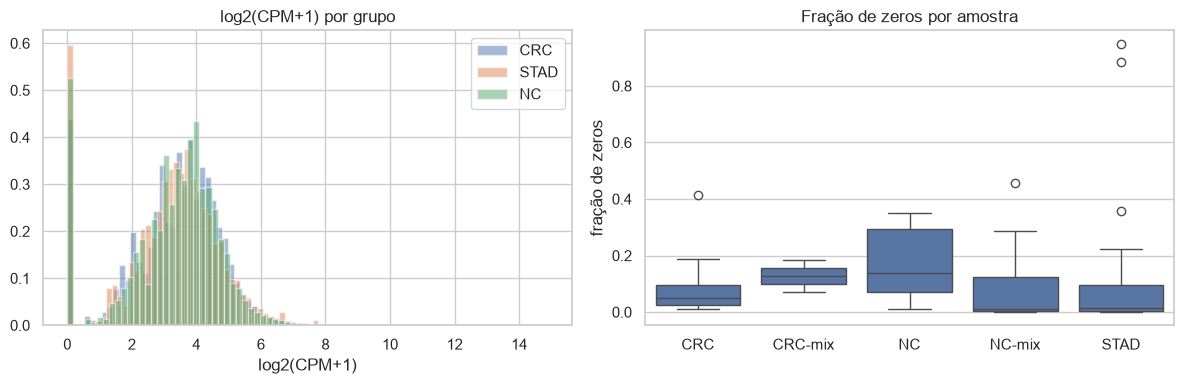

In [7]:
# distribuição dos valores em log2(CPM+1) e fração de zeros por amostra
L = np.log2(X + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for g, c in zip(["CRC", "STAD", "NC"], ["C0", "C1", "C2"]):
    ax[0].hist(L.loc[meta.grupo == g].values.ravel(), bins=80, alpha=.5, density=True, label=g, color=c)
ax[0].set(title="log2(CPM+1) por grupo", xlabel="log2(CPM+1)"); ax[0].legend()
zf = (X == 0).mean(axis=1)
sns.boxplot(x=meta["grupo"] + np.where(meta["lote_mix"], "-mix", ""), y=zf, ax=ax[1])
ax[1].set(title="Fração de zeros por amostra", xlabel="", ylabel="fração de zeros")
plt.tight_layout(); plt.savefig(FIG / "eda_distribuicao.png", dpi=150); plt.show()

## 4. PCA exploratório (não supervisionado)

PCA nos 5.000 promotores mais variáveis. Colorimos por **grupo** e por **lote** para ver o que domina a variação.
Por ser não supervisionado e só exploratório, não causa vazamento — mas **não** será usado assim no modelo final (lá a seleção fica dentro da validação).

variância explicada: [0.378 0.127 0.036 0.023 0.02 ]


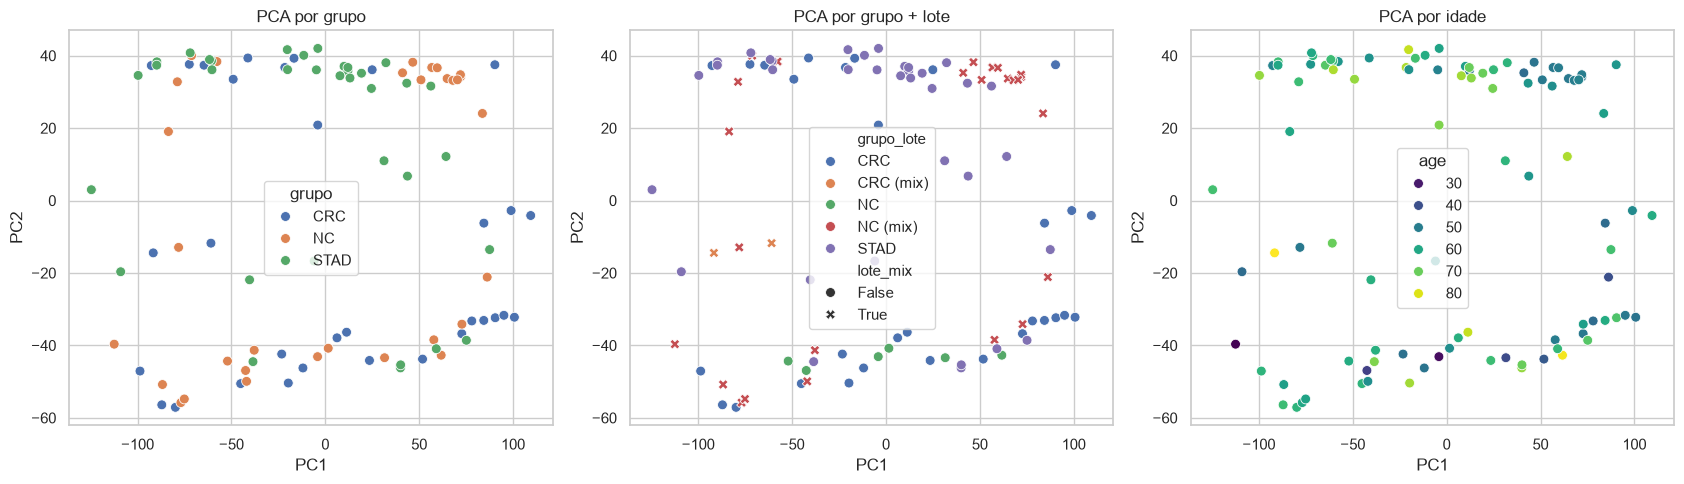

PC1         PC2        PC3      
            mean count  mean count mean count
grupo_lote                                   
CRC          9.8    30 -12.3    30 -0.4    30
CRC (mix)  -76.3     2 -13.1     2 -6.7     2
NC          -0.6     6 -43.5     6 -5.5     6
NC (mix)     4.1    25   4.2    25 -1.6    25
STAD        -6.9    35  15.8    35  2.8    35

In [8]:
Lc = L.loc[:, L.var() > 0]
top = Lc.var().sort_values(ascending=False).index[:5000]
Z = Lc[top] - Lc[top].mean()
pca = PCA(n_components=5, random_state=RANDOM_STATE).fit(Z)
pcs = pd.DataFrame(pca.transform(Z)[:, :3], index=Z.index, columns=["PC1", "PC2", "PC3"]).join(meta)
pcs["grupo_lote"] = pcs["grupo"] + np.where(pcs["lote_mix"], " (mix)", "")
print("variância explicada:", pca.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="grupo", ax=ax[0], s=50).set(title="PCA por grupo")
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="grupo_lote", style="lote_mix", ax=ax[1], s=50).set(title="PCA por grupo + lote")
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="age", palette="viridis", ax=ax[2], s=50).set(title="PCA por idade")
plt.tight_layout(); plt.savefig(FIG / "eda_pca.png", dpi=150); plt.show()
pcs.groupby("grupo_lote")[["PC1", "PC2", "PC3"]].agg(["mean", "count"]).round(1)

## 4b. O que separa os dois clusters do PC2? → **sexo**

O PCA mostra dois clusters bem separados no PC2, cada um misturando grupos. Hipótese: sexo biológico, já que a matriz inclui promotores dos cromossomos X e Y.
Isso é perigoso porque o grupo STAD é 77% masculino → o modelo poderia separar STAD de CRC pelo sexo.

In [9]:
pcs["cluster_pc2"] = np.where(pcs["PC2"] > 0, "PC2 alto", "PC2 baixo")
display(pd.crosstab(pcs["gender"], pcs["cluster_pc2"]))

# anotação gene -> cromossomo (Ensembl BioMart, hg38; arquivo versionado em data/reference/)
ann = (pd.read_csv(ROOT / "data" / "reference" / "ensembl_genes_hg38.tsv", sep="\t")
         .drop_duplicates("Gene stable ID").set_index("Gene stable ID"))
gene_id = X.columns.str.replace("promoter_", "").str.split("|").str[0].str.split(".").str[0]
feat = pd.DataFrame({"gene_id": gene_id,
                     "gene": ann["Gene name"].reindex(gene_id).values,
                     "chrom": ann["Chromosome/scaffold name"].reindex(gene_id).values}, index=X.columns)
print(feat["chrom"].value_counts(dropna=False).to_string())

cluster_pc2,PC2 alto,PC2 baixo
gender,,
female,6,33
male,45,14


chrom
1      5128
2      3874
11     3194
3      2947
17     2931
19     2891
12     2865
7      2811
6      2777
5      2766
4      2442
16     2426
X      2371
8      2283
14     2165
9      2161
10     2149
15     2075
NaN    1615
20     1361
22     1310
13     1277
18     1131
21      804
Y       497
MT       37


promotores autossômicos: 53768 de 58288
variância explicada (autossomos): [0.462 0.025 0.023 0.02  0.019]
correlação PC1 x fração de zeros: -0.63


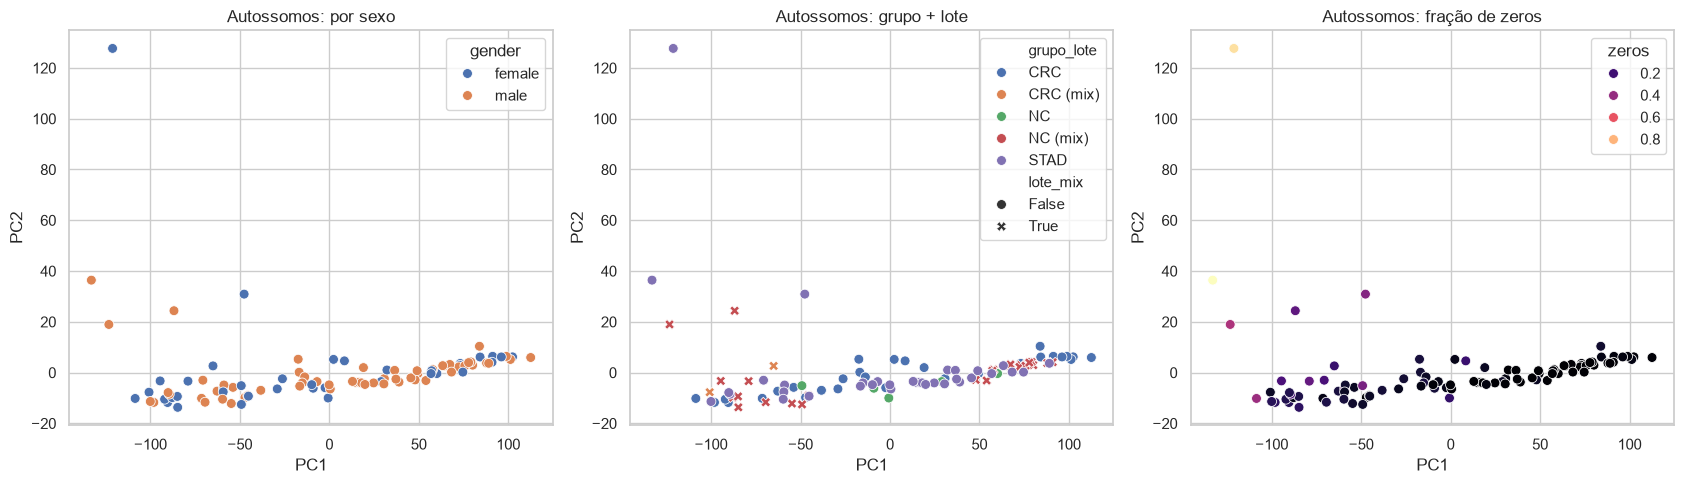

In [10]:
# Refaz o PCA só com autossomos (chr1-22): remove X, Y, MT e promotores sem anotação
AUTOSSOMOS = [str(i) for i in range(1, 23)]
auto = feat.index[feat["chrom"].isin(AUTOSSOMOS)]
print(f"promotores autossômicos: {len(auto)} de {X.shape[1]}")

La = L[auto]; La = La.loc[:, La.var() > 0]
top_a = La.var().sort_values(ascending=False).index[:5000]
Za = La[top_a] - La[top_a].mean()
pca_a = PCA(n_components=5, random_state=RANDOM_STATE).fit(Za)
pcs_a = pd.DataFrame(pca_a.transform(Za)[:, :2], index=Za.index, columns=["PC1", "PC2"]).join(meta)
pcs_a["grupo_lote"] = pcs_a["grupo"] + np.where(pcs_a["lote_mix"], " (mix)", "")
pcs_a["zeros"] = (X == 0).mean(axis=1)
print("variância explicada (autossomos):", pca_a.explained_variance_ratio_.round(3))
print("correlação PC1 x fração de zeros:", round(pcs_a[["PC1", "zeros"]].corr().iloc[0, 1], 2))

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(data=pcs_a, x="PC1", y="PC2", hue="gender", ax=ax[0], s=50).set(title="Autossomos: por sexo")
sns.scatterplot(data=pcs_a, x="PC1", y="PC2", hue="grupo_lote", style="lote_mix", ax=ax[1], s=50).set(title="Autossomos: grupo + lote")
sns.scatterplot(data=pcs_a, x="PC1", y="PC2", hue="zeros", palette="magma", ax=ax[2], s=50).set(title="Autossomos: fração de zeros")
plt.tight_layout(); plt.savefig(FIG / "eda_pca_autossomos.png", dpi=150); plt.show()

## 5. Teste do efeito de lote

Se um Random Forest consegue distinguir **controles `mix` vs controles não-`mix`** (todos saudáveis!), então o lote deixa uma assinatura forte nos dados.
Isso importa porque quase todos os controles são `mix` e quase nenhum câncer é → um classificador câncer vs saudável poderia aprender o **lote** em vez do **câncer**.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

nc = meta.index[meta.grupo == "NC"]
y_lote = meta.loc[nc, "lote_mix"].astype(int)
rf = RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)  # só 6 não-mix → 3 folds
auc = cross_val_score(rf, L.loc[nc, auto], y_lote, cv=cv, scoring="roc_auc")
print(f"AUC prevendo lote dentro dos controles saudáveis: {auc.mean():.3f} ± {auc.std():.3f}")
print("(0.5 = lote indistinguível; ~1.0 = lote muito marcado)")

AUC prevendo lote dentro dos controles saudáveis: 0.819 ± 0.153
(0.5 = lote indistinguível; ~1.0 = lote muito marcado)


## 6. Observações

- **Classes:** CRC 32 · STAD 35 · NC (saudável) 31 → razoavelmente balanceado. Para detecção: 67 câncer vs 31 saudável (~2:1).
- **Qualidade:** sem valores ausentes; ~9% de zeros; cada amostra já normalizada para 1 milhão (CPM).
- **Sexo domina o PC2** quando X/Y estão incluídos. STAD é 77% masculino → **remover chrX/chrY/MT** das features (decisão D6).
- **PC1 (46% nos autossomos) é técnico:** correlaciona com a fração de zeros (eficiência da imunoprecipitação/profundidade), não com o grupo. Os 2 CRC `mix` são outliers extremos nesse eixo.
- **Lote `mix`:** um RF distingue controles `mix` de controles não-`mix` com AUC ~0.82 → há assinatura de lote. Como 25/31 controles são `mix` e só 2/67 cânceres são, a tarefa câncer vs saudável fica **parcialmente confundida com lote**. Mitigação: análise de sensibilidade avaliando separadamente os 6 NC não-mix e os 2 CRC mix (amostras que "cruzam" o lote).
- **Idade:** controles são ~10 anos mais jovens (mediana 50 vs 62–64) → outro possível *confounder* da detecção; citar na discussão.
- **TOO (CRC vs STAD)** é menos afetada por lote (quase tudo não-mix), mas sofre com o desbalanço de sexo → resolvido removendo X/Y.